# Spatiotemporal Prediction of Electric Vehicle Charging Demand
### Data Science Lab Project — UrbanEV (Shenzhen) analysis notebook

**Goal:** predict the energy (kWh) delivered by EV chargers in each of Shenzhen's 275 charging
zones during the **next hour** (supervised regression).

**Models compared:** Linear Regression · Random Forest Regressor · LightGBM Regressor.

This notebook uses the same `src/` modules as the web application, so preprocessing, features
and results are identical in both.

| Section | Content |
|---|---|
| 1 | Dataset inspection |
| 2 | Data preprocessing |
| 3 | Data integration (zone, station and charger information) |
| 4 | Feature engineering and chronological split |
| 5 | Exploratory data analysis: correlation analysis |
| 6 | Model training |
| 7 | Model evaluation and comparison |
| 8 | Model interpretation |
| 9 | Final model selection |
| 10 | Walk-forward forecasting (dataset period) |
| 11 | Future-date estimates |
| 12 | Conclusion, limitations and future scope |

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src import config
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
print("Project root:", ROOT)
print("Dataset folder:", config.DATA_DIR)

Project root: C:\Users\HP\OneDrive\Desktop\EV
Dataset folder: C:\Users\HP\OneDrive\Desktop\EV\data\Dataset\UrbanEVDataset\UrbanEVDataset


## 1. Dataset inspection

The UrbanEV dataset is **not** ordinary row-wise data. Each hourly file in
`charge_1hour/` is a **wide** table: one `time` column plus one column per zone ID.
The files are CSV (the proposal mentioned Excel; the provided dataset is CSV).

In [2]:
from src.data_loader import (check_dataset, inspect_dataset, load_hourly_wide,
                             price_schedule_check, check_5min_consistency)
check_dataset()
summary = inspect_dataset()
pd.DataFrame(summary["hourly_files"]).T

,rows (hours),zone columns,start,end,missing values,negative values,duplicate timestamps,non-hourly gaps,zero share,min,max,mean
volume,4344,275,2022-09-01 00:00:00,2023-02-28 23:00:00,0,0,0,0,0.0546,0.0,16732.5,261.465
volume-11kw,4344,275,2022-09-01 00:00:00,2023-02-28 23:00:00,0,0,0,0,0.0546,0.0,5073.0,102.866
occupancy,4344,275,2022-09-01 00:00:00,2023-02-28 23:00:00,0,0,0,0,0.027,0.0,373.0,17.866
duration,4344,275,2022-09-01 00:00:00,2023-02-28 23:00:00,0,0,0,0,0.0547,0.0,207.583,13.106
e_price,4344,275,2022-09-01 00:00:00,2023-02-28 23:00:00,0,0,0,0,0.0,0.238,1.8,0.951
s_price,4344,275,2022-09-01 00:00:00,2023-02-28 23:00:00,0,0,0,0,0.0074,0.0,1.45,0.724


In [3]:
volume_wide = load_hourly_wide("volume")
print("volume.csv shape (hours x zones):", volume_wide.shape)
print("dtypes:", volume_wide.dtypes.value_counts().to_dict())
volume_wide.iloc[:5, :8]

volume.csv shape (hours x zones): (4344, 275)
dtypes: {dtype('float32'): 275}


,102,104,105,106,107,108,109,110
time,,,,,,,,
2022-09-01 00:00:00,56.291668,11.083333,60.375000,78.750000,90.125000,71.458336,58.916668,40.250000
2022-09-01 01:00:00,50.458332,9.333333,72.625000,81.666664,100.333336,76.708336,51.916668,43.166668
2022-09-01 02:00:00,55.708332,12.833333,73.208336,89.250000,94.500000,75.833336,58.333332,43.166668
2022-09-01 03:00:00,57.750000,12.541667,67.666664,74.083336,89.541664,80.208336,62.416668,28.000000
2022-09-01 04:00:00,58.333332,11.958333,69.708336,78.166664,88.666664,75.541664,56.583332,42.000000


In [4]:
for name in ["zones", "zone_hour_records", "zone_info", "station_info_cleaned",
             "station_info_raw", "pile_rated_power", "adjacency", "distance", "volume_11kw_leakage"]:
    print(f"{name}: {summary[name]}")

zones: 275
zone_hour_records: 1194600
zone_info: {'rows': 275, 'columns': ['TAZID', 'longitude', 'latitude', 'charge_count', 'area', 'perimeter'], 'zones match hourly columns': True, 'zones with missing (0,0) coordinates': [348]}
station_info_cleaned: {'stations': 1362, 'columns': ['station_id', 'longitude', 'latitude', 'charge_count', 'TAZID']}
station_info_raw: {'stations': 1682, 'columns': ['station_id', 'longitude', 'latitude', 'slow_count', 'fast_count', 'charge_count', 'TAZID'], 'slow+fast == charge_count': True}
pile_rated_power: {'piles': 22650, 'stations covered': 1552, 'AC piles': 19556, 'DC piles': 3094}
adjacency: {'shape': [275, 275], 'columns match hourly order': True, 'values': [0, 1], 'self-loops on diagonal': True, 'asymmetric pairs': 20, 'zones with no neighbours': 4, 'mean neighbours': 4.36}
distance: {'shape': [275, 275], 'columns match hourly order': True, 'max distance (m)': 78680.3}
volume_11kw_leakage: {'share of rows with volume_11kw <= volume': 0.9935, 'share 

In [5]:
zone_raw = pd.read_csv(config.ZONE_INFO_FILE)
station_raw = pd.read_csv(config.RAW_STATION_INFO_FILE)
piles = pd.read_csv(config.PILE_POWER_FILE)
display(zone_raw.head(), station_raw.head(), piles.head())

,TAZID,longitude,latitude,charge_count,area,perimeter
0,1066,113.910301,22.521287,40,1.577893e+06,5119.3013
1,1068,113.918680,22.517837,271,1.405269e+06,5460.2638
2,1096,113.919902,22.531428,70,1.074909e+06,4437.0676
3,326,113.931887,22.535775,106,1.963022e+06,6447.5728
4,1085,113.925789,22.521524,59,3.878395e+05,2688.3240


,station_id,longitude,latitude,slow_count,fast_count,charge_count,TAZID
0,1001,113.784724,22.714121,20,0,20,559
1,1002,113.785002,22.725900,22,0,22,558
2,1003,113.787971,22.735538,6,0,6,558
3,1004,113.788126,22.693449,6,5,11,596
4,1005,113.788126,22.693449,6,5,11,596


,pile_id,power,pileType,station_id
0,10010001.0,7.0,AC,1001.0
1,10010002.0,7.0,AC,1001.0
2,10010003.0,7.0,AC,1001.0
3,10010004.0,7.0,AC,1001.0
4,10010005.0,7.0,AC,1001.0


**Relationships between files (verified):**
* zone columns of all hourly files = `TAZID` in `zone-information.csv` = column order of `adj.csv` and `distance.csv`;
* `station_information.csv` maps `station_id → TAZID`; `pile_rated_power.csv` maps `pile_id → station_id`;
* summed slow + fast pile counts of the raw station file equal each zone's `charge_count` exactly.

**Two extra checks:** prices follow a fixed daily time-of-use schedule, so they are known in advance,
and the hourly volume equals the sum of the twelve 5-minute volumes.

In [6]:
print("Share of zone-days whose 24-h price profile equals the previous day:", price_schedule_check())
print("5-minute vs hourly consistency:", check_5min_consistency())

Share of zone-days whose 24-h price profile equals the previous day: {'e_price': 0.9739, 's_price': 0.971}
5-minute vs hourly consistency: {'five_min_rows': 52128, 'five_min_zones': 275, 'same zone columns': True, 'max_abs_difference_kwh': 0.000434, 'mean_abs_difference_kwh': 3e-06, 'hourly_equals_sum_of_5min': True}


## 2. Data preprocessing

The six wide files are reshaped into one **long panel** (one row per zone-hour) and validated.

In [7]:
from src.data_loader import load_panel
from src.preprocessing import validate_panel, clean_panel

panel = clean_panel(load_panel())
print("Long panel shape:", panel.shape)
display(panel.head())
validate_panel(panel)

Long panel shape: (1194600, 8)


,time,zone,volume,volume_11kw,occupancy,duration,e_price,s_price
0,2022-09-01 00:00:00,102,56.291668,56.291668,17.0,8.833333,0.924,0.856
1,2022-09-01 01:00:00,102,50.458332,50.458332,16.0,8.166667,0.924,0.856
2,2022-09-01 02:00:00,102,55.708332,55.708332,16.0,8.916667,0.924,0.856
3,2022-09-01 03:00:00,102,57.750000,57.750000,16.0,9.166667,0.924,0.856
4,2022-09-01 04:00:00,102,58.333332,58.333332,17.0,9.250000,0.924,0.856


{'rows': 1194600,
 'zones': 275,
 'timestamps': 4344,
 'duplicate (time, zone) rows': 0,
 'missing values': {'volume': 0,
  'volume_11kw': 0,
  'occupancy': 0,
  'duration': 0,
  'e_price': 0,
  's_price': 0},
 'negative values': {'volume': 0,
  'volume_11kw': 0,
  'occupancy': 0,
  'duration': 0,
  'e_price': 0,
  's_price': 0},
 'complete grid': True}

**Preprocessing decisions and assumptions**

| Check | Result | Action |
|---|---|---|
| Missing values | 0 in all files | none needed (forward-fill kept as a safeguard) |
| Duplicate (time, zone) rows | 0 | none needed (drop kept as a safeguard) |
| Negative values | 0 | clip at 0 kept as a safeguard |
| Time gaps | none, 4,344 consecutive hours | – |
| Data types | float64 | converted to float32 (memory), zone → int32 |
| Zone 348 coordinates (0, 0) | missing location | replaced by mean of its stations' coordinates |
| `volume_11kw` | component of the target | excluded from predictors (target leakage) |
| Same-hour occupancy / duration | unknown at forecast time | only 1-hour lags are used |
| Scaling | needed by Linear Regression only | `StandardScaler` fitted on training data inside a pipeline |

## 3. Data integration

Static zone attributes are joined to every zone-hour using the verified zone ID. Charger capacity
is derived from the station and pile files.

In [8]:
from src.data_loader import load_zone_info
zones = load_zone_info()
display(zones.head())
zones.describe().T.round(2)

,zone,longitude,latitude,num_piles,area,perimeter,slow_count,fast_count,fast_share,avg_pile_kw,capacity_kw
0,1066,113.910301,22.521287,40,1.577893e+06,5119.3013,40,0,0.00000,5.775000,231.000000
1,1068,113.918680,22.517837,271,1.405269e+06,5460.2638,263,8,0.02952,7.440529,2016.383260
2,1096,113.919902,22.531428,70,1.074909e+06,4437.0676,70,0,0.00000,8.451220,591.585366
3,326,113.931887,22.535775,106,1.963022e+06,6447.5728,106,0,0.00000,6.009434,637.000000
4,1085,113.925789,22.521524,59,3.878395e+05,2688.3240,59,0,0.00000,5.398305,318.500000


,count,mean,std,min,25%,50%,75%,max
zone,275.0,733.77,310.09,102.00,527.50,737.00,1004.50,1173.00
longitude,275.0,114.05,0.15,113.77,113.92,114.04,114.13,114.50
latitude,275.0,22.62,0.08,22.47,22.55,22.62,22.69,22.82
num_piles,275.0,85.24,78.10,4.00,28.00,58.00,114.50,446.00
area,275.0,3583954.77,5380920.93,387839.48,1417430.66,2317791.15,3761469.95,49933877.00
perimeter,275.0,8456.07,6061.33,2688.32,5275.10,6842.33,8850.51,44371.05
slow_count,275.0,74.39,72.72,0.00,22.00,49.00,105.00,355.00
fast_count,275.0,10.85,30.91,0.00,0.00,0.00,4.00,274.00
fast_share,275.0,0.11,0.24,0.00,0.00,0.00,0.02,1.00
avg_pile_kw,275.0,22.26,39.93,3.50,6.83,7.00,9.93,258.74


In [9]:
ratio = panel.merge(zones[["zone", "capacity_kw"]], on="zone")
ratio = ratio.volume / ratio.capacity_kw
print(f"Hourly energy / zone capacity: max = {ratio.max():.3f}, 99th percentile = {ratio.quantile(.99):.3f}")
print("-> demand never exceeds installed charger power: the capacity feature is physically consistent.")

Hourly energy / zone capacity: max = 1.000, 99th percentile = 0.667
-> demand never exceeds installed charger power: the capacity feature is physically consistent.


## 4. Feature engineering

**Prediction horizon:** next hour. A row (zone, hour *t*) has target `volume` at *t*; all features
use information from hour *t − 1* or earlier, or information known in advance for hour *t*
(calendar, holidays, tariff prices, static zone attributes).

Lags are computed per zone on the (time × zone) matrix, so a shift never crosses zones.
The first 168 hours (incomplete weekly history) are dropped.

In [10]:
from src.feature_engineering import (load_features, leakage_checks, FEATURES, LAG_FEATURES,
                                     PRICE_FEATURES, CALENDAR_FEATURES, STATIC_FEATURES)
feats = load_features()
print("Feature table:", feats.shape)
for group, cols in [("Lag / history", LAG_FEATURES), ("Tariff", PRICE_FEATURES),
                    ("Calendar", CALENDAR_FEATURES), ("Zone", STATIC_FEATURES)]:
    print(f"{group:14s} ({len(cols)}): {cols}")
print("Total model inputs:", len(FEATURES))
feats[["time", "zone", "split", "volume"] + FEATURES].head()

Feature table: (1148400, 33)
Lag / history  (7): ['volume_lag1', 'volume_lag24', 'volume_lag168', 'volume_roll24_mean', 'occupancy_lag1', 'duration_lag1', 'neighbor_volume_lag1']
Tariff         (2): ['e_price', 's_price']
Calendar       (9): ['hour', 'day', 'dayofweek', 'is_weekend', 'is_holiday', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos']
Zone           (7): ['num_piles', 'fast_share', 'avg_pile_kw', 'capacity_kw', 'area', 'longitude', 'latitude']
Total model inputs: 25


,time,zone,split,volume,volume_lag1,volume_lag24,volume_lag168,volume_roll24_mean,occupancy_lag1,duration_lag1,neighbor_volume_lag1,e_price,s_price,hour,day,dayofweek,is_weekend,is_holiday,hour_sin,hour_cos,dow_sin,dow_cos,num_piles,fast_share,avg_pile_kw,capacity_kw,area,longitude,latitude
0,2022-09-08,102,train,66.500000,66.500000,66.5,56.291668,66.500000,19.0,10.000000,39.666668,0.924000,0.856000,0,8,3,0,0,0.0,1.0,0.433884,-0.900969,30.0,0.100000,11.950000,358.500,7.144193e+05,114.102959,22.540413
1,2022-09-08,104,train,16.916666,7.000000,10.5,11.083333,4.812500,1.0,1.000000,127.385414,0.923333,0.760000,0,8,3,0,0,0.0,1.0,0.433884,-0.900969,19.0,0.000000,6.631579,126.000,1.171734e+06,114.113983,22.553131
2,2022-09-08,105,train,49.000000,48.416668,66.5,60.375000,45.743057,14.0,7.250000,53.958332,1.124167,0.750000,0,8,3,0,0,0.0,1.0,0.433884,-0.900969,93.0,0.000000,6.284946,584.500,7.725567e+05,114.120850,22.551266
3,2022-09-08,106,train,91.000000,83.416664,112.0,78.750000,91.072914,45.0,11.916667,44.799999,1.170000,0.633333,0,8,3,0,0,0.0,1.0,0.433884,-0.900969,114.0,0.000000,7.000000,798.000,5.787174e+05,114.121880,22.544271
4,2022-09-08,107,train,80.500000,77.583336,87.5,90.125000,68.067711,17.0,11.583333,57.604164,0.926364,0.737273,0,8,3,0,0,0.0,1.0,0.433884,-0.900969,95.0,0.042105,8.125000,771.875,8.887169e+05,114.130386,22.544861


`month` is created but **not** used as an input: training covers Sep–Dec while the test set is February,
a value never seen in training, and six months cannot teach yearly seasonality.

### Chronological split
All zones of one timestamp are always in the same split.

In [11]:
feats.groupby("split").agg(rows=("time", "size"), start=("time", "min"), end=("time", "max")).loc[["train", "val", "test"]]

,rows,start,end
split,,,
train,759000,2022-09-08,2022-12-31 23:00:00
val,204600,2023-01-01,2023-01-31 23:00:00
test,184800,2023-02-01,2023-02-28 23:00:00


In [12]:
pd.Series(leakage_checks(feats, panel), name="passed").to_frame()

,passed
lag1 == volume at t-1,True
lag24 == volume at t-24,True
lag168 == volume at t-168,True
roll24 uses t-24..t-1 only,True
no feature equals same-hour target column,True
leaky columns excluded from FEATURES,True
train < val < test (no time overlap),True
each timestamp in exactly one split,True
no missing feature values,True


## 5. Exploratory data analysis: correlation analysis

The EDA is limited to **Pearson correlation**, computed on the **training period only**.
Same-hour occupancy, duration and `volume_11kw` are included only to discuss them; they are not inputs.

In [13]:
from src.eda import run_correlation_analysis, plot_heatmap
corr_res = run_correlation_analysis(feats)
fig = plot_heatmap(corr_res["matrix"])
plt.show()

In [14]:
corr_res["target"].style.format({"pearson_r": "{:.3f}"}).background_gradient(
    subset=["pearson_r"], cmap="RdBu_r", vmin=-1, vmax=1)

,feature,pearson_r,strength,role
0,volume_lag24,0.964,strong positive,model input
1,volume_lag168,0.948,strong positive,model input
2,volume_lag1,0.937,strong positive,model input
3,volume_roll24_mean,0.871,strong positive,model input
4,capacity_kw,0.657,moderate positive,model input
5,fast_share,0.507,moderate positive,model input
6,volume_11kw,0.499,moderate positive,excluded - part of the target (leakage)
7,avg_pile_kw,0.464,moderate positive,model input
8,duration,0.440,moderate positive,excluded - same-hour value unknown at forecast time
9,duration_lag1,0.419,moderate positive,model input


### Multicollinearity among model inputs (|r| ≥ 0.8)

In [15]:
corr_res["pairs"].round(3)

,feature_1,feature_2,pearson_r
0,volume_lag24,volume_lag168,0.946
1,occupancy_lag1,duration_lag1,0.919
2,fast_share,avg_pile_kw,0.919
3,volume_lag1,volume_lag24,0.914
4,volume_lag1,volume_lag168,0.900
5,volume_lag1,volume_roll24_mean,0.872
6,volume_lag24,volume_roll24_mean,0.872
7,volume_lag168,volume_roll24_mean,0.855


### Pooled vs within-zone correlation
Pooled correlation mixes *large zone vs small zone* with *busy hour vs quiet hour*.
The median correlation inside each zone over time isolates the second effect.

In [16]:
corr_res["within"].round(3)

,feature,pooled_r,median_within_zone_r
0,volume_lag1,0.937,0.934
1,volume_lag24,0.964,0.560
2,volume_lag168,0.948,0.387
3,volume_roll24_mean,0.871,0.494
4,occupancy_lag1,0.381,0.672
5,duration_lag1,0.419,0.927
6,neighbor_volume_lag1,-0.031,0.302
7,e_price,-0.230,-0.404
8,s_price,-0.119,0.285
9,hour_cos,0.049,0.281


### Interpretation (generated from the values above)

In [17]:
for note in corr_res["notes"]:
    print("•", note)

• Strongest predictors among model inputs: volume_lag24 (r = 0.96), volume_lag168 (r = 0.95), volume_lag1 (r = 0.94). Recent demand in the same zone is the best single indicator of next-hour demand.
• Same-hour occupancy (r = 0.40) and duration (r = 0.44) move with demand but are only known after the hour ends, so the models use their 1-hour lags instead (r = 0.38 and 0.42).
• volume_11kw has r = 0.50 with the target because it is a component of it (energy from <=11 kW chargers); using it would leak the answer.
• Electricity price r = -0.23 and service price r = -0.12: prices follow a daily time-of-use tariff, so part of their correlation reflects the time of day rather than a direct price effect.
• Zone size/capacity: num_piles r = 0.30, capacity_kw r = 0.66 - larger zones deliver more energy on average.
• hour has r = -0.07: Pearson only measures LINEAR association, and the daily cycle is not linear in the hour number, which is why sine/cosine hour features are used.
• neighbor_volum

## 6. Model training

All three models use the same 25 features, the same training period (8 Sep – 31 Dec 2022) and
random seed 42. January 2023 is used only for LightGBM early stopping and for model selection.

| Model | Key settings |
|---|---|
| Linear Regression | `StandardScaler` → `LinearRegression` (scaler fitted on training data only) |
| Random Forest | 100 trees, max depth 18, min 20 samples per leaf, 50% features per split, 30% rows per tree |
| LightGBM | learning rate 0.05, 63 leaves, min 50 samples per leaf, 80% row/column sampling, early stopping (100 rounds) |

Set `RETRAIN = False` to reuse the saved models instead of training again.

In [18]:
from src.train_models import MODEL_NAMES, build_model, train_all
for name in MODEL_NAMES:
    print(name, "->", build_model(name))

Linear Regression -> Pipeline(steps=[('scaler', StandardScaler()), ('model', LinearRegression())])
Random Forest -> RandomForestRegressor(max_depth=18, max_features=0.5, max_samples=0.3,
                      min_samples_leaf=20, n_jobs=-1, random_state=42)
LightGBM -> LGBMRegressor(colsample_bytree=0.8, learning_rate=0.05, min_child_samples=50,
              n_estimators=3000, n_jobs=-1, num_leaves=63, random_state=42,
              subsample=0.8, subsample_freq=1, verbose=-1)


In [19]:
RETRAIN = True
log = train_all(feats, MODEL_NAMES, force=RETRAIN)
pd.DataFrame(log).T

[train] Linear Regression ...


[done] Linear Regression: 1.0 s, 0.0 MB
[train] Random Forest ...


[done] Random Forest: 63.1 s, 23.6 MB
[train] LightGBM ...


[done] LightGBM: 24.9 s, 0.8 MB


,model,train_rows,n_features,training_seconds,trained_at,file_size_mb,best_iteration
Linear Regression,Linear Regression,759000,25,1.0,2026-11-12T15:47:22,0.0,NaN
LightGBM,LightGBM,759000,25,24.9,2026-11-12T15:48:53,0.8,369
Random Forest,Random Forest,759000,25,63.1,2026-11-12T15:48:26,23.6,NaN


## 7. Model evaluation and comparison

Metrics: **MAE**, **MSE**, **RMSE** and **R²**. Predictions are clipped at 0 kWh.
Two naive reference forecasts (no learning) show how much the models add:
*repeat last hour* (lag-1) and *repeat the same hour last week* (lag-168).

In [20]:
from src.evaluate_models import run_evaluation, EVAL_DIR
eval_res = run_evaluation(feats)
comparison = eval_res["comparison"]
comparison.style.format({"MAE": "{:.2f}", "MSE": "{:,.0f}", "RMSE": "{:.2f}", "R2": "{:.4f}"}) \
    .highlight_min(subset=["MAE", "MSE", "RMSE"], color="#d6f0e4").highlight_max(subset=["R2"], color="#d6f0e4")

[eval] best model: LightGBM (lowest test RMSE: LightGBM)


,model,MAE,MSE,RMSE,R2
0,Linear Regression,48.70,"33,800",183.85,0.9535
1,Random Forest,35.56,"26,215",161.91,0.9639
2,LightGBM,34.28,"20,356",142.67,0.9720
3,Naive (lag-1),51.49,"82,382",287.02,0.8867
4,Naive (lag-168),77.19,"104,836",323.78,0.8558


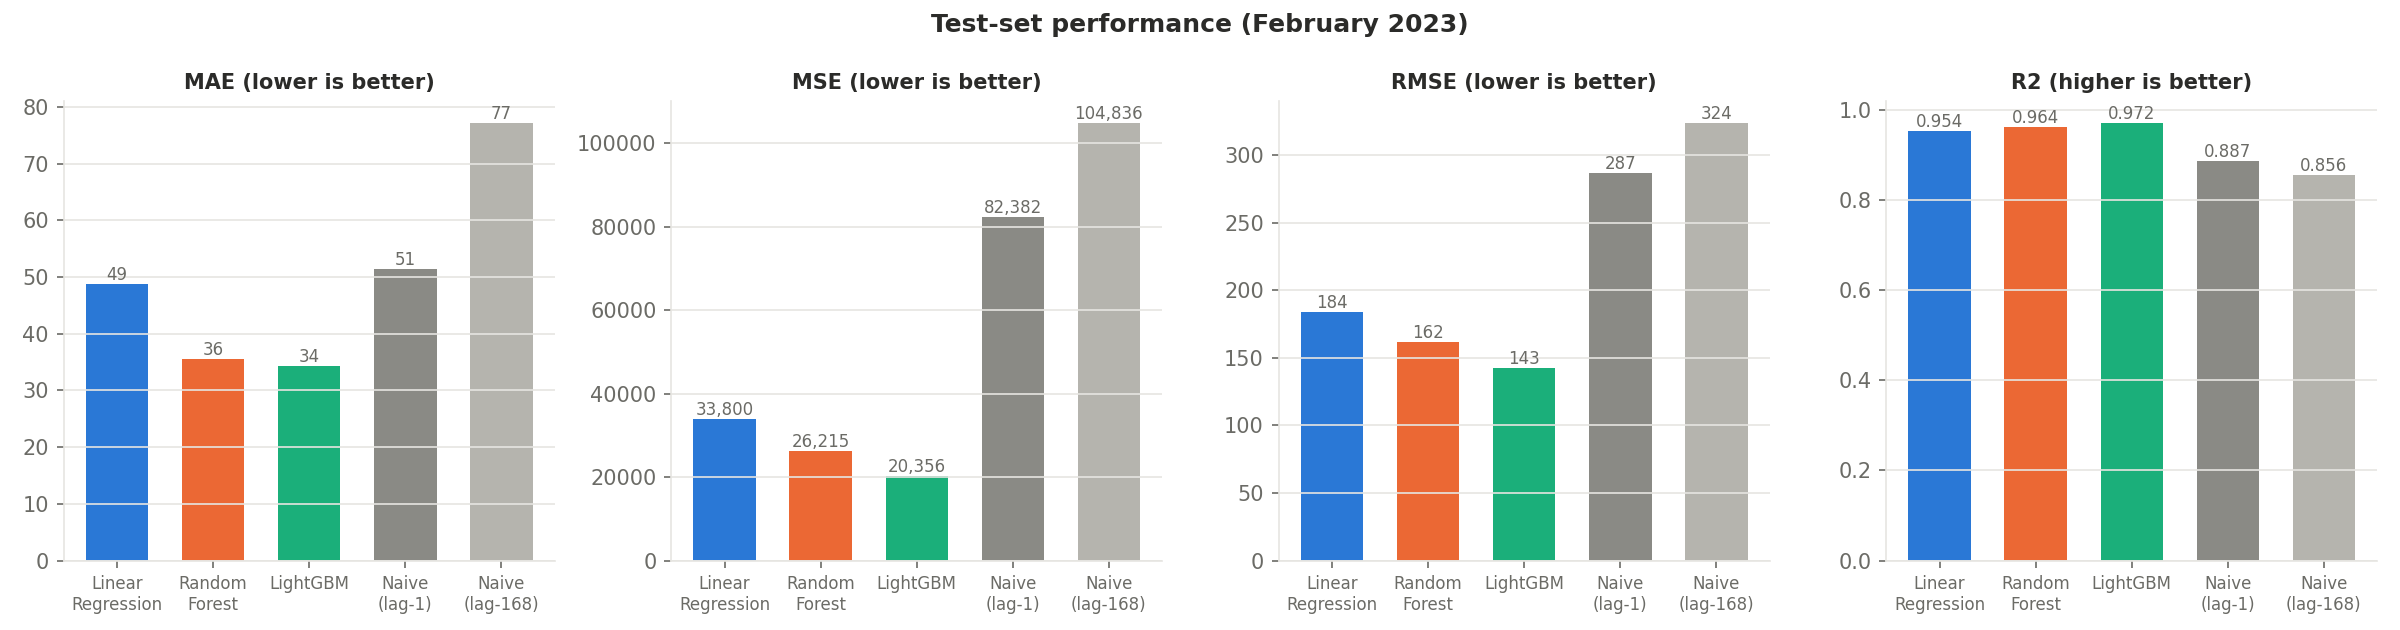

In [21]:
display(Image(str(EVAL_DIR / "metric_comparison.png")))

### Train / validation / test: checking for overfitting and underfitting

In [22]:
eval_res["metrics"].pivot(index="model", columns="split", values=["RMSE", "R2"]) \
    .reindex(columns=["train", "val", "test"], level=1).round(3)

RMSE                       R2              
split                train      val     test  train    val   test
model                                                            
LightGBM           123.473  141.371  142.673  0.981  0.959  0.972
Linear Regression  190.911  176.151  183.847  0.955  0.937  0.954
Naive (lag-1)      318.248  240.305  287.022  0.874  0.883  0.887
Naive (lag-168)    289.884  362.636  323.783  0.895  0.733  0.856
Random Forest      157.930  152.185  161.911  0.969  0.953  0.964

## 8. Model interpretation

### Linear Regression coefficients (standardised features: kWh per +1 standard deviation)

In [23]:
eval_res["coefficients"].round(2)

,feature,coefficient
0,volume_lag24,417.209991
1,volume_lag1,251.440002
2,volume_lag168,219.779999
3,duration_lag1,30.670000
4,occupancy_lag1,-28.309999
5,volume_roll24_mean,10.200000
6,hour_sin,-9.130000
7,hour,-7.460000
8,dayofweek,-5.970000
9,dow_cos,-4.730000


### Random Forest and LightGBM feature importance

In [24]:
eval_res["importance"].pivot(index="feature", columns="model", values="importance") \
    .sort_values("LightGBM", ascending=False).round(4)

model,LightGBM,Random Forest
feature,,
volume_lag24,0.6323,0.4453
volume_lag168,0.2052,0.2983
volume_lag1,0.1288,0.1567
duration_lag1,0.0060,0.0109
hour,0.0048,0.0019
hour_cos,0.0030,0.0017
capacity_kw,0.0029,0.0058
occupancy_lag1,0.0024,0.0009
volume_roll24_mean,0.0024,0.0637


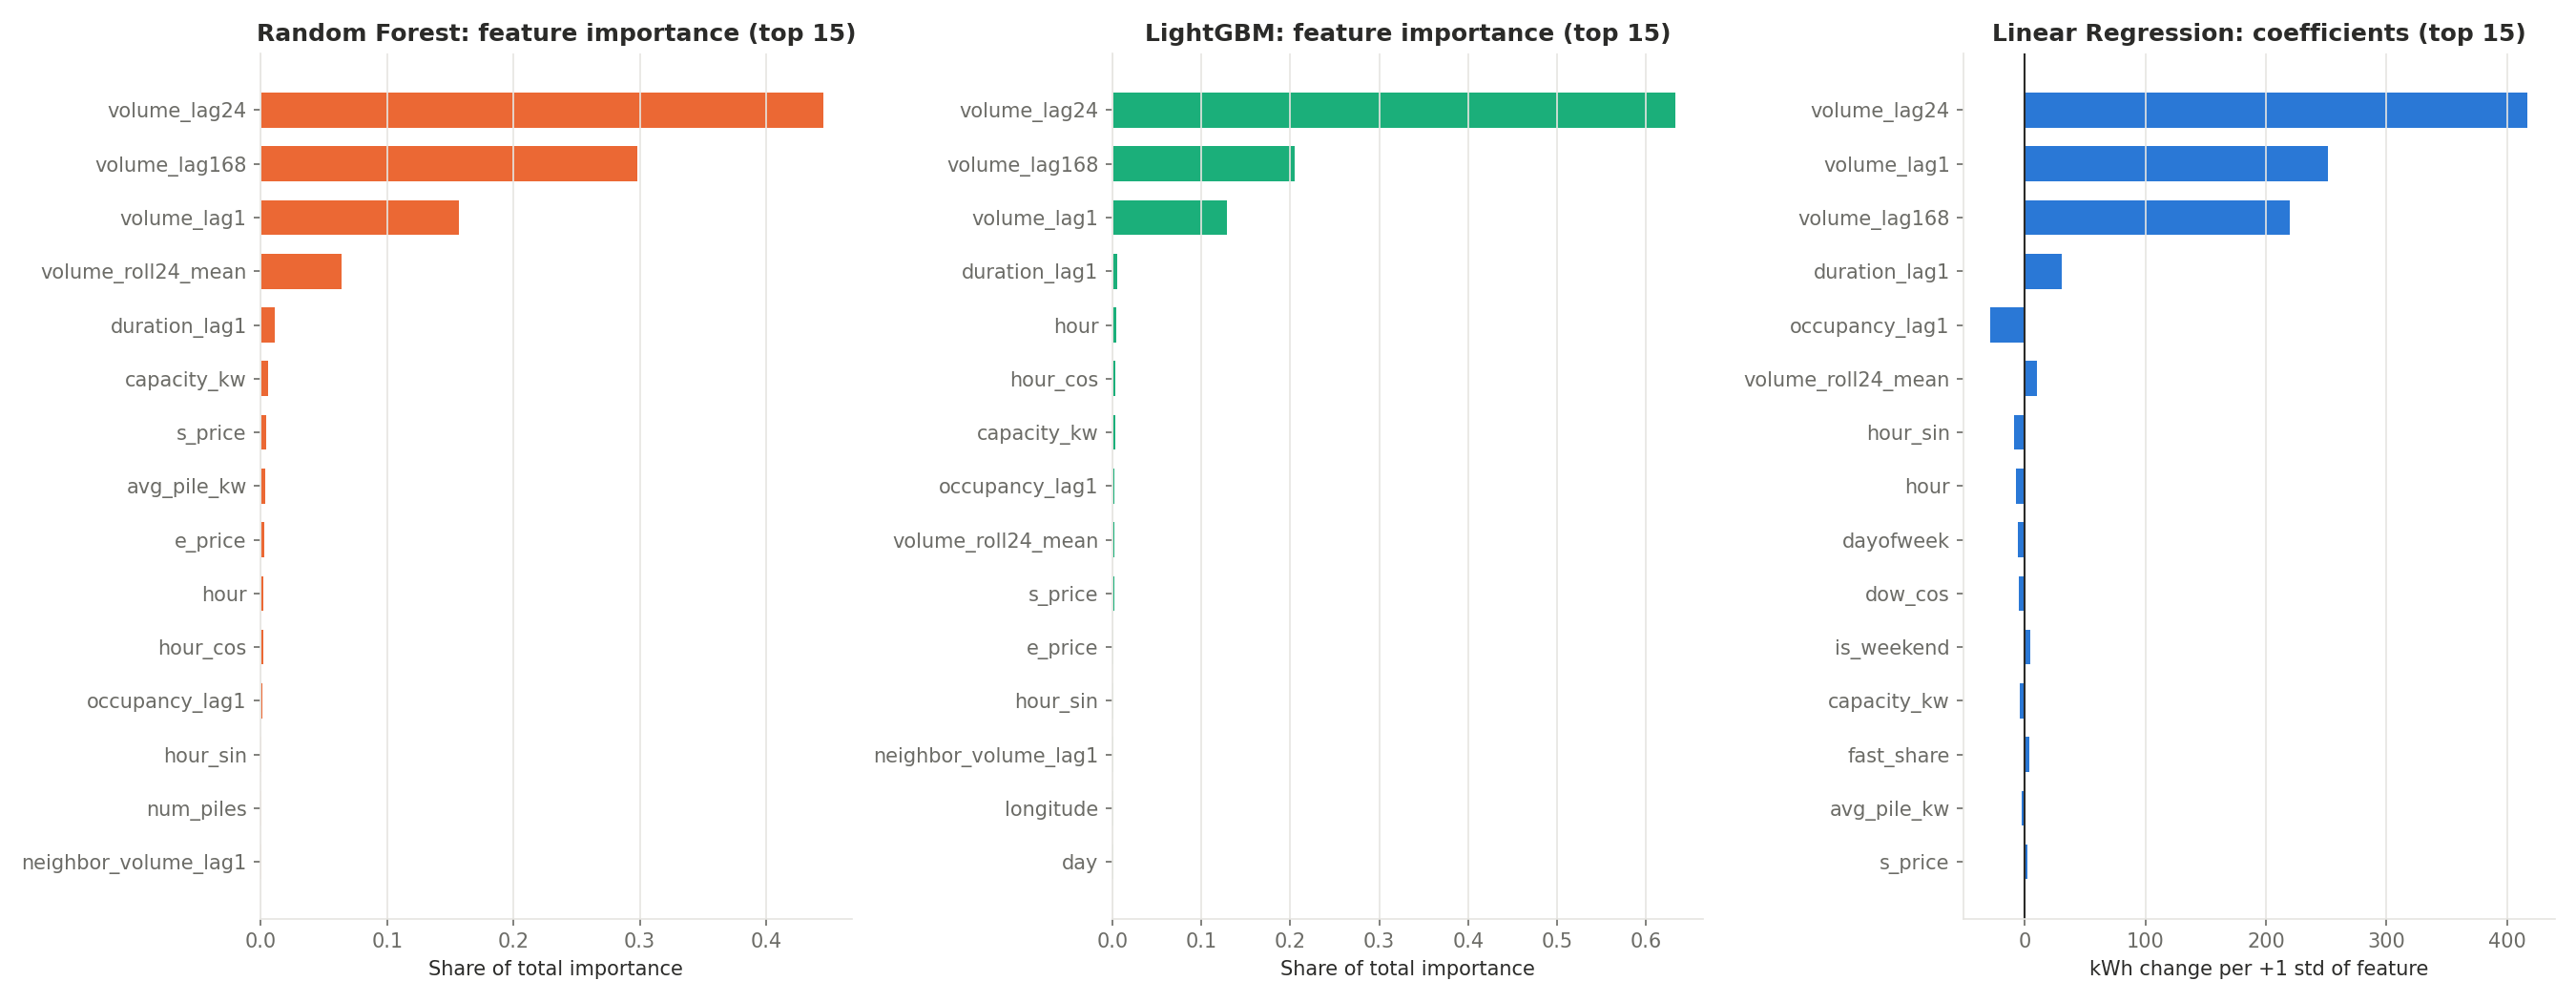

In [25]:
display(Image(str(EVAL_DIR / "feature_importance.png")))

### Actual vs predicted

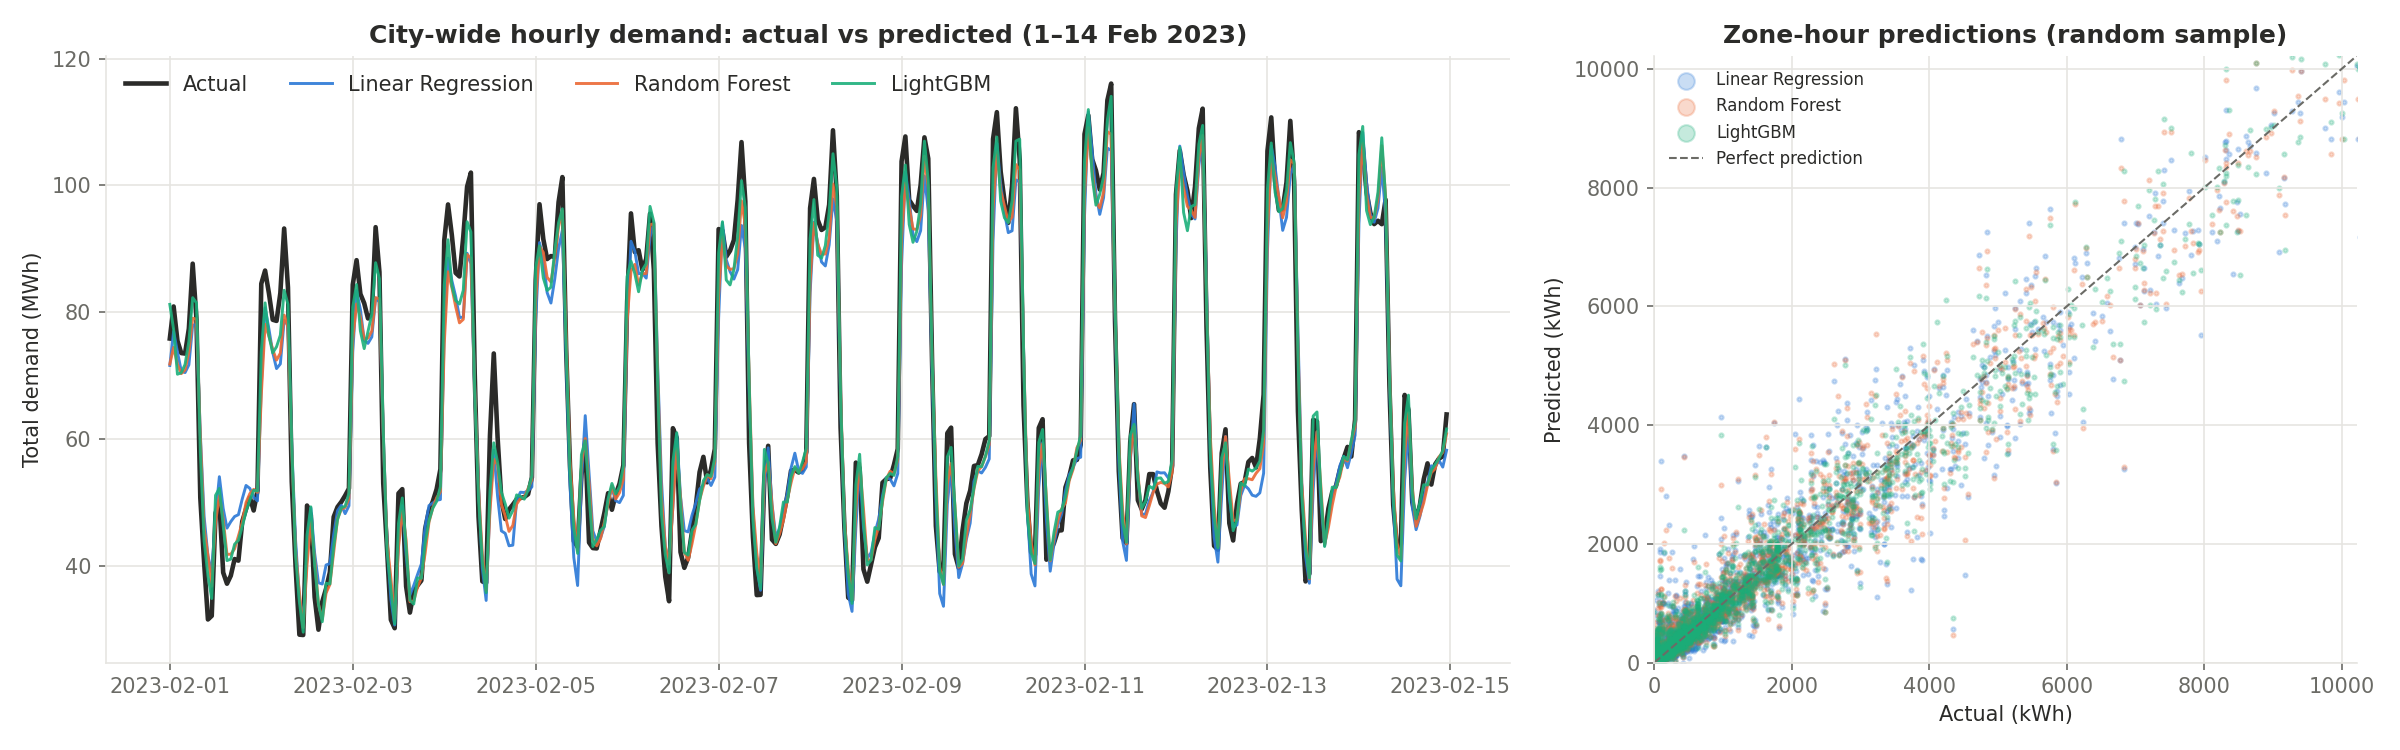

In [26]:
display(Image(str(EVAL_DIR / "actual_vs_predicted.png")))

### Residual analysis

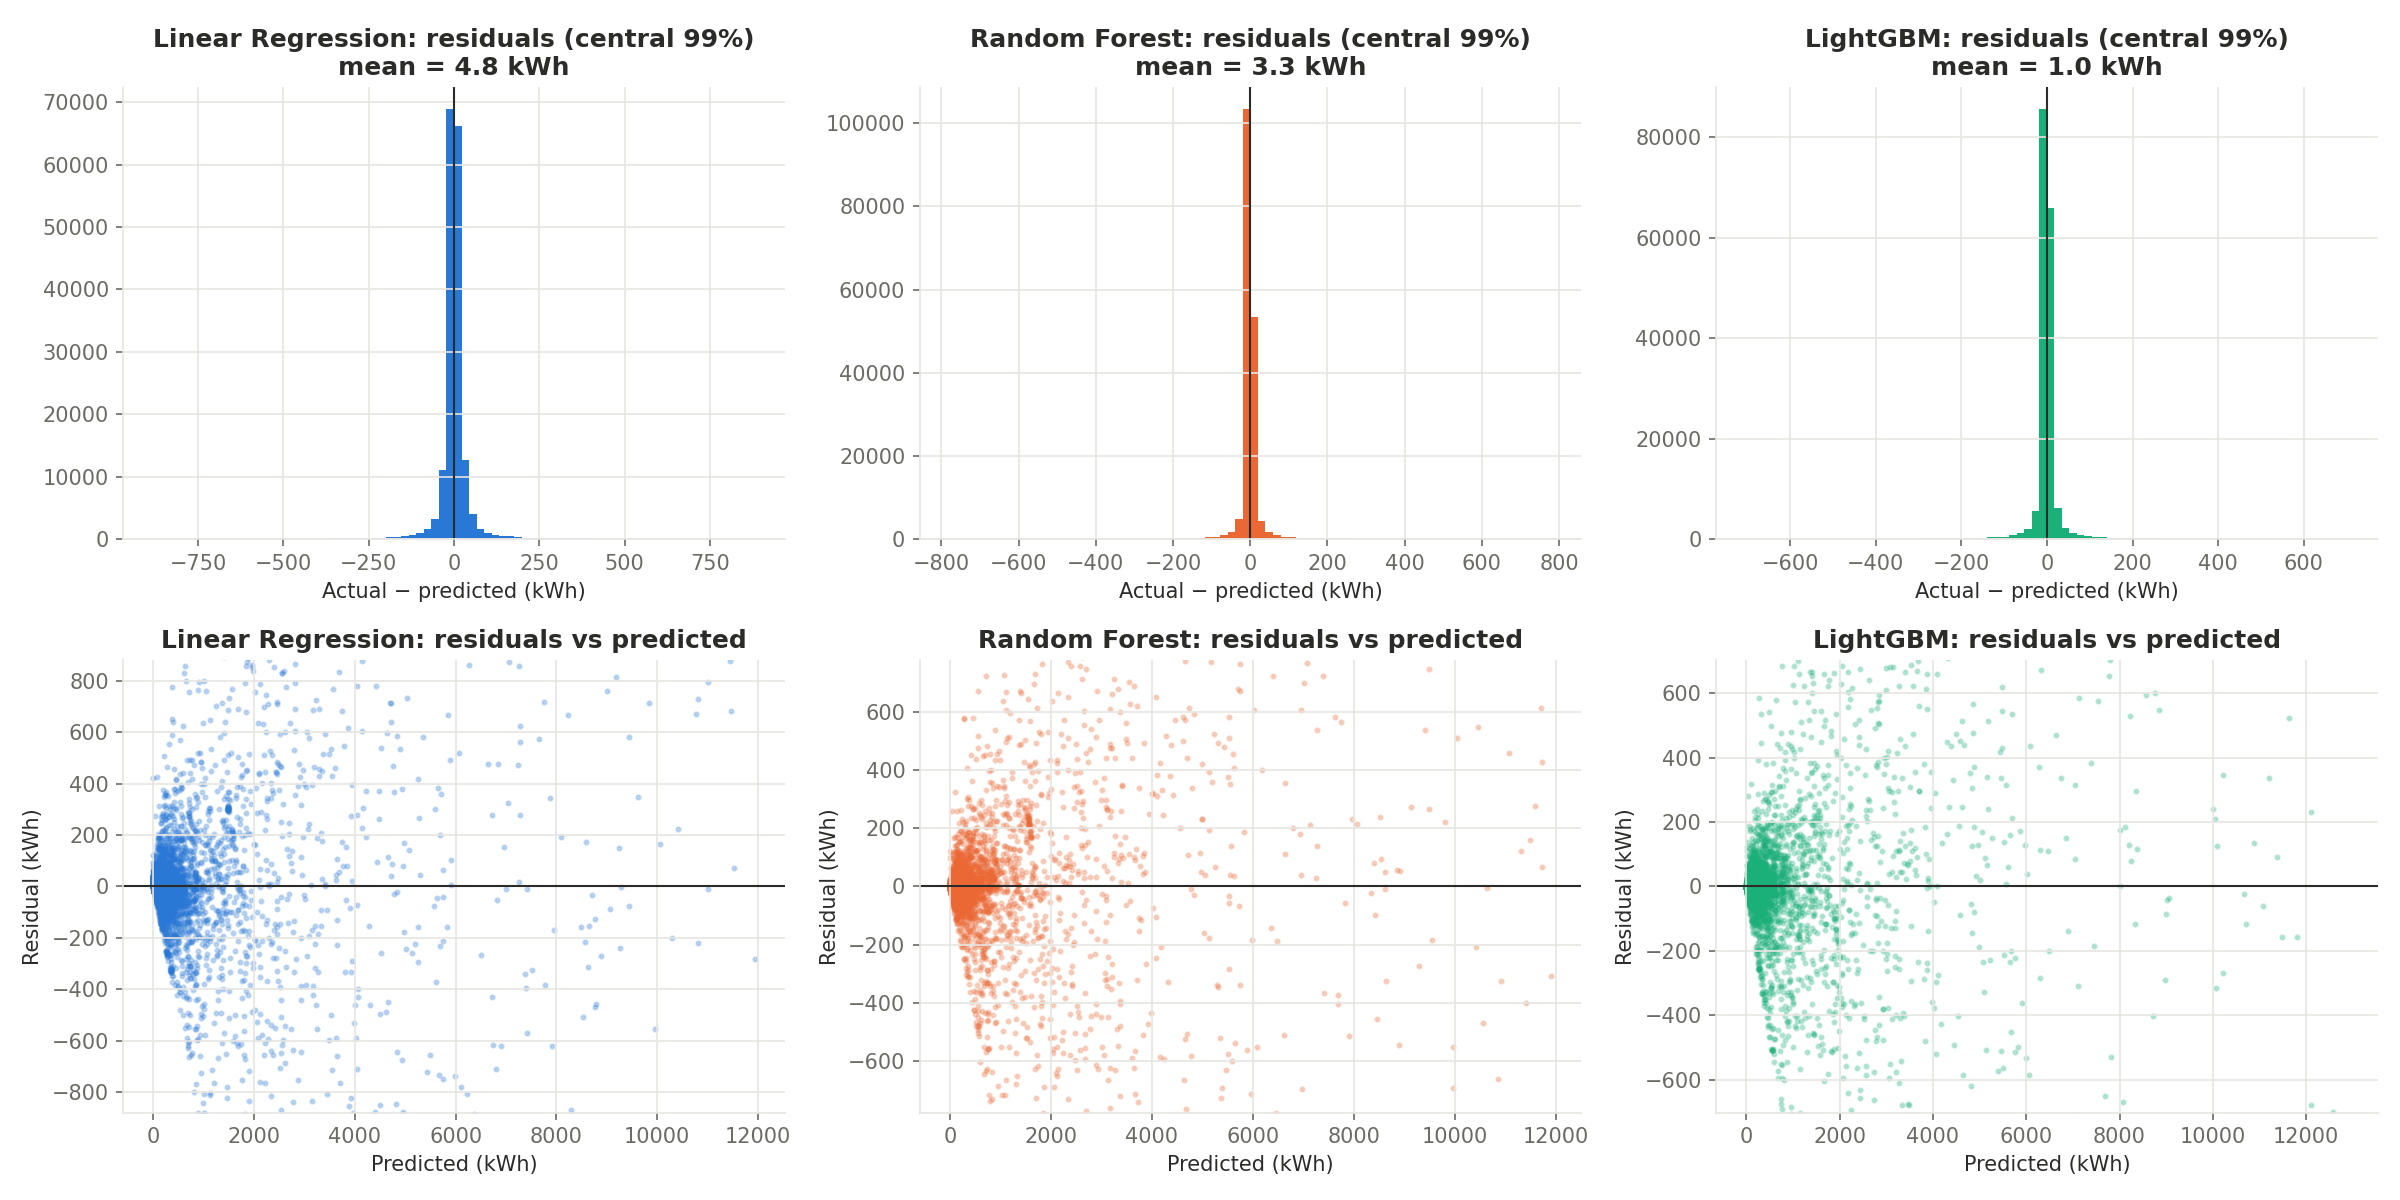

,Linear Regression,Random Forest,LightGBM
count,184800.00,184800.00,184800.00
mean,4.76,3.33,1.03
std,183.79,161.88,142.67
min,-4141.41,-3897.29,-4166.17
25%,-10.11,-2.72,-3.82
50%,0.10,-0.10,-0.82
75%,11.34,2.36,3.17
max,6082.63,5769.20,4613.62


In [27]:
display(Image(str(EVAL_DIR / "residuals.png")))
preds = pd.read_parquet(EVAL_DIR / "test_predictions.parquet")
pd.DataFrame({m: (preds.actual - preds[m]).describe() for m in MODEL_NAMES}).round(2)

## 9. Final model selection

Rule: the model with the **lowest validation RMSE** is selected; the test set is only used to confirm
the choice (choosing on test data would make the reported test score optimistic).

In [28]:
best = json.loads((config.MODELS_DIR / "best_model.json").read_text())
c = comparison.set_index("model")
b = best["best_model"]
print("Selected model:", b)
print("Validation RMSE:", best["validation_rmse"])
print("Confirmed on test set:", best["selection_confirmed_on_test"])
print()
print(f"Test performance of {b}: MAE {c.at[b, 'MAE']:.1f} kWh | RMSE {c.at[b, 'RMSE']:.1f} kWh | R² {c.at[b, 'R2']:.4f}")
for m in MODEL_NAMES + ["Naive (lag-1)"]:
    if m != b:
        print(f"  RMSE reduction vs {m}: {100 * (1 - c.at[b, 'RMSE'] / c.at[m, 'RMSE']):.1f}%")

Selected model: LightGBM
Validation RMSE: {'Linear Regression': 176.151, 'Random Forest': 152.185, 'LightGBM': 141.371}
Confirmed on test set: True

Test performance of LightGBM: MAE 34.3 kWh | RMSE 142.7 kWh | R² 0.9720
  RMSE reduction vs Linear Regression: 22.4%
  RMSE reduction vs Random Forest: 11.9%
  RMSE reduction vs Naive (lag-1): 50.3%


**Why the boosted model performs best (interpretation of the results above):**
* Gradient boosting builds trees sequentially, each one correcting the remaining errors, so it captures
  non-linear patterns (daily cycle, zone size, interaction of recent and weekly demand) that a single
  linear equation cannot.
* Compared with Random Forest (independent trees averaged), boosting focuses on the hard cases and,
  with early stopping on the validation month, stops before overfitting.
* Linear Regression has a higher error on its own training data, a sign of **underfitting**: the
  relationship is not purely linear. The tree models show only small train → test gaps, so there is
  little overfitting.

## 10. Walk-forward forecasting (dataset period, Oct 2022 – Feb 2023)

To let users pick **any date** in the dataset and compare the prediction with the real value,
every month from October to February is predicted by models trained **only on the months before it**
(expanding window). LightGBM's early stopping uses the last 7 days of each fold's own training data.

| Predicted month | Trained on |
|---|---|
| Oct 2022 | 8 Sep – 30 Sep |
| Nov 2022 | 8 Sep – 31 Oct |
| Dec 2022 | 8 Sep – 30 Nov |
| Jan 2023 | 8 Sep – 31 Dec |
| Feb 2023 | 8 Sep – 31 Jan |

Computing this takes about 15 minutes, so saved results are loaded by default
(set `RECOMPUTE = True` to run it again).

In [29]:
from src.walk_forward import run_walk_forward, load_walk_forward, WF_PREDICTIONS
RECOMPUTE = False
if RECOMPUTE or not WF_PREDICTIONS.exists():
    wf_preds, wf_monthly = run_walk_forward(feats)
else:
    wf_preds, wf_monthly = load_walk_forward()
print("Walk-forward predictions:", wf_preds.shape)
wf_monthly.pivot(index="month", columns="model", values="RMSE")[MODEL_NAMES].round(1)

Walk-forward predictions: (996600, 6)


model,Linear Regression,Random Forest,LightGBM
month,,,
2022-10,186.7,174.6,168.5
2022-11,183.7,170.5,154.5
2022-12,201.9,185.2,161.2
2023-01,176.2,152.2,143.6
2023-02,182.0,157.2,140.0
Oct-Feb (all),186.4,168.6,154.2


In [30]:
fig, ax = plt.subplots(figsize=(9, 4))
from src.plot_style import MODEL_COLORS, apply_matplotlib_style
apply_matplotlib_style()
per_month = wf_monthly[wf_monthly.month != "Oct-Feb (all)"]
for m in MODEL_NAMES:
    d = per_month[per_month.model == m]
    ax.plot(d.month, d.RMSE, marker="o", lw=2, color=MODEL_COLORS[m], label=m)
ax.set_title("Walk-forward RMSE by predicted month")
ax.set_ylabel("RMSE (kWh)")
ax.legend(frameon=False)
plt.show()
wf_monthly[wf_monthly.month == "Oct-Feb (all)"][["model", "MAE", "RMSE", "R2"]].round(3)

,model,MAE,RMSE,R2
15,Linear Regression,51.287,186.393,0.951
16,Random Forest,38.002,168.556,0.960
17,LightGBM,36.762,154.178,0.966


The ranking (LightGBM < Random Forest < Linear Regression in error) holds in **every month**, and
errors fall as more training months become available, so the conclusion of Section 9 is stable over time.

## 11. Future-date estimates (after Feb 2023)

Next-hour models need the previous hours' real demand, which does not exist after the dataset ends.
For future dates, **profile models** use only inputs known for any date: calendar and holidays,
typical tariff prices, zone attributes and the zone's typical demand pattern learnt from training data
(zone × hour, zone × weekday, zone × weekday/weekend × hour). They predict demand **relative to the
zone's typical demand**, which lets weekday, holiday and price effects be learnt across zones.

Evaluation: trained on 1 Sep 2022 – 31 Jan 2023, tested on February 2023, and compared with a
reference forecast that simply uses the zone's typical demand. The final models are then retrained on
all six months.

In [31]:
from src.profile_model import PROFILE_EVAL, PROFILE_INFO, train_profile_models
RETRAIN_PROFILE = False
profile_eval = train_profile_models() if (RETRAIN_PROFILE or not PROFILE_INFO.exists()) else pd.read_csv(PROFILE_EVAL)
profile_eval[["model", "MAE", "MSE", "RMSE", "R2"]].round(3)

,model,MAE,MSE,RMSE,R2
0,Reference (zone typical demand),81.089,95017.977,308.250,0.869
1,Linear Regression,80.110,91155.703,301.920,0.875
2,Random Forest,83.783,108124.264,328.823,0.851
3,LightGBM,85.891,116433.375,341.223,0.840


In [32]:
pe = profile_eval.set_index("model")
best_future = json.loads(PROFILE_INFO.read_text())["best_model"]
ref = "Reference (zone typical demand)"
print("Best future-date model:", best_future)
print(f"RMSE {pe.at[best_future, 'RMSE']:.1f} vs reference {pe.at[ref, 'RMSE']:.1f} "
      f"({100 * (1 - pe.at[best_future, 'RMSE'] / pe.at[ref, 'RMSE']):.1f}% better)")
print(f"Next-hour LightGBM RMSE on the same month (walk-forward): "
      f"{wf_monthly[(wf_monthly.month == '2023-02') & (wf_monthly.model == 'LightGBM')].RMSE.iloc[0]:.1f}")

Best future-date model: Linear Regression
RMSE 301.9 vs reference 308.2 (2.1% better)
Next-hour LightGBM RMSE on the same month (walk-forward): 140.0


**Interpretation.** Without recent real demand, the best estimate is close to the zone's typical
demand for that hour; the models improve on it only slightly, and the simple Linear Regression
generalises best here (the tree models fit Sep–Jan specifics that do not carry over). Future
estimates are therefore much less precise than next-hour forecasts, and they cannot reflect changes
after February 2023 such as growth in EV numbers. The app labels them clearly as estimates.

**Not year-specific.** The year is not an input: six months of data contain no information about year-to-year change, so the same zone, weekday and hour give nearly the same estimate in any year. The app therefore calls these *typical-pattern estimates*. Extending the data artificially was rejected, because a model trained on copied or synthetic years would only learn the assumptions used to create them.

## 12. Conclusion, limitations and future scope

**Achievements**
* Inspected and validated the full UrbanEV dataset (275 zones × 4,344 hours = 1,194,600 zone-hours);
  all files, matrices and identifiers were verified to align.
* Built a leakage-free next-hour forecasting pipeline with 25 features, including a spatial
  neighbour-demand feature, holiday flags and charger-capacity features; all leakage checks pass.
* Trained and fairly compared Linear Regression, Random Forest and LightGBM on a strict
  chronological split; all three clearly outperform the naive baselines.
* Confirmed the result month by month with walk-forward forecasting (Oct 2022 – Feb 2023).
* Added future-date estimates from profile models trained on all six months.
* Deployed everything in a Streamlit application where users pick any date: dataset-period dates
  are compared with actual demand, later dates receive clearly-labelled estimates.

**Key findings**
* Recent demand history, above all the same hour on the previous day, is the strongest
  predictor of next-hour demand.
* Zones with more fast chargers and more installed power deliver more energy.
* Demand is highest overnight, when electricity prices are lowest.
* Pooled correlations can hide real relationships (e.g. neighbouring-zone demand) that appear
  clearly within individual zones.

**Practical applications:** dynamic pricing and capacity management for operators, queue-avoidance
advice for drivers, charger-siting decisions for planners, and EV-load anticipation for grid operators.

**Limitations**
* Only six months of data, so no yearly seasonality; the test month (February) includes the period just after Spring Festival.
* Results are specific to Shenzhen.
* No weather data; holidays are represented by a simple flag.
* Small inconsistencies between source files (e.g. charger counts vs rated-power list) were documented, not corrected.
* Future-date estimates rely on Sep 2022 – Feb 2023 patterns only and are close to typical-demand averages;
  they cannot capture growth after February 2023 and cannot be checked against actual data.

**Future scope**
* Add weather and event data; forecast several hours or days ahead.
* Compare with sequence and graph models (LSTM, STGCN) that use the adjacency matrix directly.
* Connect the application to live charging data for real-time forecasting.
* Apply the pipeline to other cities to test generalisation.

In [33]:
print("Notebook finished. Artifacts saved in:", config.ARTIFACTS_DIR)

Notebook finished. Artifacts saved in: C:\Users\HP\OneDrive\Desktop\EV\artifacts
